# Triangular perturbation solver for the signature Riccati equation

Reference: [`doc/riccati_perturbation.md`](../doc/riccati_perturbation.md), implemented in
[`signature/riccati_perturbation.py`](../signature/riccati_perturbation.py).

The **diffusive dilation** $\hat\delta_\varepsilon$ acts on letters by $\text{time}\rightsquigarrow\varepsilon\,\text{time}$,
$\text{state}\rightsquigarrow\sqrt\varepsilon\,\text{state}$ and, being a homomorphism, is diagonal on words:
$\hat\delta_\varepsilon v=\varepsilon^{\|v\|/2}v$ with the **diffusive grade**

$$\|v\| \;=\; 2\,|v|_{\text{time}}+\textstyle\sum_s |v|_s .$$

Since $\hat\delta_\varepsilon\widehat{\mathbb W}_T\overset{d}{=}\widehat{\mathbb W}_{\varepsilon T}$, the ansatz
$\psi^{\hat\delta_\varepsilon p}=\sum_k\psi_k\,\varepsilon^{k/2}$ is at once a *small-terminal-data* and a
*small-time* expansion. Matching powers of $\varepsilon^{1/2}$ in the Riccati equation gives

$$\dot\psi_k+\mathcal L\psi_k+\tfrac12\sum_{\ell=0}^{k}\psi_\ell|_s\,\text{ш}\,\psi_{k-\ell}|_s=0,
\qquad \psi_k(T)=\vec\pi_k(p)=\!\!\sum_{\|v\|=k}\!\!p^v v,$$

with $\mathcal L\ell=\ell|_{\text{time}}+\tfrac12\sum_s\ell|_{ss}$.

## Why it is triangular — and exactly solvable

1. $\psi_k\in F_k=\operatorname{span}\{v:\|v\|\le k\}$. $\mathcal L$ lowers the grade by 2 and
   $\psi_\ell|_s\,\text{ш}\,\psi_m|_s$ has grade $\le \ell+m-2$, so $F_k$ is invariant.
2. $F_0=\operatorname{span}\{\varnothing\}$, hence $\psi_0|_s=0$. This kills **both** the $\ell=0$ and the
   $\ell=k$ term of the quadratic sum, so the equation for $\psi_k$ is **linear in $\psi_k$** with a source
   built only from $\psi_1,\dots,\psi_{k-1}$. Solve $k=0,1,2,\dots$ in order.
3. $\mathcal L$ is nilpotent and the source is polynomial in $\tau=T-t$, so each $\psi_k$ is a
   **polynomial in $\tau$ of degree $\le\lfloor k/2\rfloor$**. There is no ODE to integrate and no time grid.

**A stronger fact, found numerically and used below.** Tracking the $\tau$-degree as well, the $\tau^j$
coefficient of $\psi_k$ is supported on words of grade **exactly** $k-2j$. So each pair
(grade $\gamma$, $\tau$-degree $j$) is carried by *exactly one* order $k=\gamma+2j$: the hierarchy is not
merely triangular but **diagonal**, and truncating at order $K$ keeps the **triangle**
$\{\gamma+2j\le K\}$ — a joint truncation in word grade and time degree, unlike the
"all words of length $\le N$" truncation an ODE integrator commits to.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
if "../" not in sys.path:
    sys.path.append("../")

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import jax, jax.numpy as jnp
from scipy.special import roots_hermite

import signature.tensor_algebra as ta
from signature import riccati_perturbation as rp
from signature.ode_integration import ode_solver, step_fun_euler, step_fun_pece

PALETTE = ["#5C7B55", "#C0714A", "#C9A84C", "#A8C5A0", "#8B5A6B", "#4A5568"]
plt.rcParams["figure.figsize"]        = ((1 + np.sqrt(5)) / 2 * 5, 5)
plt.rcParams["figure.autolayout"]     = True
plt.rcParams["patch.force_edgecolor"] = False
plt.rcParams["axes.grid"]             = True
plt.rcParams["axes.prop_cycle"]       = matplotlib.cycler(color=PALETTE)
IMG = "images/riccati_perturbation"
import os; os.makedirs(IMG, exist_ok=True)

## 1. Structure of the hierarchy

Verifying the three claims above, plus the diagonality, on the test problem
$\langle p,\widehat{\mathbb W}_T\rangle=-W_T^4$ (i.e. $p=-24\cdot\mathbf{1111}$, `dim=1`, state-only so
there is no time letter and the grade degenerates to the word length).

In [2]:
dim, trunc, K = 1, 18, 18
stab = ta.get_shuffle_table(trunc, dim)
p    = ta.from_word(1111, trunc, dim) * (-24.0)

psi, info = rp.perturbation_hierarchy(p, K, stab, time_letter=None, check=True)
print("structural checks (psi_k in F_k, psi_0|_s = 0, deg_tau psi_k <= k//2): PASSED")
print("tau-degree of psi_k :", info["max_tau_degree"])
print("   (-1 = identically zero: for a grade-4 p only the orders k = 4, 8, 12, 16 are populated)")

# diagonality: every populated (order k, tau-degree j) cell must carry grade EXACTLY k - 2j
support = rp.support_by_order(psi, info["grades"])
bad = {(k, j): g for (k, j), g in support.items() if g != [k - 2 * j]}
print("\ndiagonality violations:", bad if bad else "none")
for (k, j), g in sorted(support.items()):
    if k <= 8: print(f"   psi_{k}, tau^{j}:  grades present = {g}   (k - 2j = {k - 2*j})")

structural checks (psi_k in F_k, psi_0|_s = 0, deg_tau psi_k <= k//2): PASSED
tau-degree of psi_k : [-1, -1, -1, -1, 2, -1, -1, -1, 4, -1, -1, -1, 6, -1, -1, -1, 8, -1, -1]
   (-1 = identically zero: for a grade-4 p only the orders k = 4, 8, 12, 16 are populated)

diagonality violations: none
   psi_4, tau^0:  grades present = [4]   (k - 2j = 4)
   psi_4, tau^1:  grades present = [2]   (k - 2j = 2)
   psi_4, tau^2:  grades present = [0]   (k - 2j = 0)
   psi_8, tau^1:  grades present = [6]   (k - 2j = 6)
   psi_8, tau^2:  grades present = [4]   (k - 2j = 4)
   psi_8, tau^3:  grades present = [2]   (k - 2j = 2)
   psi_8, tau^4:  grades present = [0]   (k - 2j = 0)


In [3]:
# The graded route and the plain tau-Taylor recursion agree exactly on the triangle gamma + 2j <= K
d = rp.assert_routes_agree(p, 14, ta.get_shuffle_table(10, 1), time_letter=None)
print(f"dim=1: max |graded - Taylor| inside the triangle = {d:.2e}")

stab2 = ta.get_shuffle_table(7, 2)
p_cm  = ta.tensor_prod(ta.from_word(22, 7, 2) * (-4.0), ta.from_word(1, 7, 2))
d2 = rp.assert_routes_agree(p_cm, 10, stab2, time_letter=1)
print(f"dim=2: max |graded - Taylor| inside the triangle = {d2:.2e}")
print("\n=> summing the hierarchy at eps=1 IS the recursive tau-Taylor method for g' = R g.")
print("   The grading buys structure and a better truncation, not a different number.")

dim=1: max |graded - Taylor| inside the triangle = 0.00e+00


dim=2: max |graded - Taylor| inside the triangle = 0.00e+00

=> summing the hierarchy at eps=1 IS the recursive tau-Taylor method for g' = R g.
   The grading buys structure and a better truncation, not a different number.


## 2. The headline analytic output: the Taylor series in $T$

No ODE integrator produces this. Because every $\psi_k$ is an exact polynomial in $\tau$, the empty-word
component of $\sum_k\psi_k(T)$ is an exact polynomial in $T$ — the small-time expansion of
$\log\mathbb E[e^{-W_T^4}]$, in closed form, with rational coefficients.

In [4]:
series = rp.taylor_series_in_T(psi)
terms  = [(j, c) for j, c in enumerate(series) if abs(c) > 1e-9]
print("log E[exp(-W_T^4)] = " + " ".join(f"{c:+g} T^{j}" for j, c in terms) + " + ...")

# independent check against the moment expansion of E[exp(-s X^4)], X ~ N(0,1), s = T^2
from math import factorial
import numpy.polynomial.polynomial as P
mom = np.array([(-1.0)**n / factorial(n) * np.prod(np.arange(1, 4*n, 2)) for n in range(5)])  # E[X^4n]/n!
log_s = np.zeros(5)                                     # log of the s-series, by Newton's identity
for n in range(1, 5):
    log_s[n] = mom[n] - sum(k * log_s[k] * mom[n-k] for k in range(1, n)) / n
print("\nmoment-expansion check (coefficients of s = T^2):", np.round(log_s[1:], 6))
print("hierarchy                                        :", np.array([c for _, c in terms]))

r = [abs(terms[i+1][1] / terms[i][1]) for i in range(len(terms)-1)]
print(f"\nratios |c_(m+1)/c_m|      : {np.round(r, 1)}")
print(f"implied radius sqrt(c/c') : {np.round(1/np.sqrt(r), 3)}  -> SHRINKING")
print("=> zero radius of convergence: an ASYMPTOTIC series (Laplace Example 5.1).")

log E[exp(-W_T^4)] = -3 T^2 +48 T^4 -1584 T^6 +78336 T^8 + ...

moment-expansion check (coefficients of s = T^2): [-3.0000e+00  4.8000e+01 -1.5840e+03  7.8336e+04]
hierarchy                                        : [-3.0000e+00  4.8000e+01 -1.5840e+03  7.8336e+04]

ratios |c_(m+1)/c_m|      : [16.  33.  49.5]
implied radius sqrt(c/c') : [0.25  0.174 0.142]  -> SHRINKING
=> zero radius of convergence: an ASYMPTOTIC series (Laplace Example 5.1).


The coefficients grow factorially, so the series is asymptotic: it has an **optimal truncation order**
that shrinks as $T$ grows, and pushing past it makes the answer worse. That is the central limitation of
the single-shot method and it is intrinsic to the problem, not to the implementation — for
$\langle p,\widehat{\mathbb W}_T\rangle=-W_T^4$ the transform is $C^\infty$ but not analytic at $T=0$.

## 3. Comparison with Euler and PECE — $\mathbb{E}[e^{-W_T^4}]$

In [5]:
xh, wh = roots_hermite(120)
def truth(T):
    # log E[exp(-W_T^4)] by Gauss-Hermite (exact to ~1e-12)
    return float(np.log(wh @ np.exp(-(np.sqrt(2*T)*xh)**4) / np.sqrt(np.pi)))

@jax.jit
def ode_fun(psi_, args):     # R psi = 1/2 psi|_11 + 1/2 (psi|_1)^{sh 2}   (dim = 1)
    return psi_.proj(11)*0.5 + ta.shuffle_pow(psi_.proj(1), 2, args["shuffle_table"])*0.5

def ode_value(T, n_steps, step_fun):
    res = ode_solver(fun=ode_fun, step_fun=step_fun, t_grid=jnp.linspace(0.0, T, n_steps+1),
                     init=p, args={"shuffle_table": stab})
    return float(res.array[0])

Ts = [0.01, 0.02, 0.03, 0.05, 0.08, 0.10, 0.15, 0.20, 0.25]
rows = []
for T in Ts:
    tr = truth(T)
    ks, e_opt = rp.optimal_order(psi, T, tr)
    ps = rp.partial_sums(psi, T)
    rows.append(dict(T=T, truth=tr,
                     euler=ode_value(T, 4000, step_fun_euler),
                     pece=ode_value(T, 4000, step_fun_pece),
                     pert_opt=ps[ks], k_opt=ks, pert_full=ps[-1]))

def show(v):
    return "   blow-up" if (not np.isfinite(v) or abs(v) > 1e3) else f"{v:>10.7f}"
print(f"{'T':>6} {'truth':>11} {'Euler':>11} {'PECE':>11} {'pert K*':>11} {'K*':>4} {'pert K=18':>11}")
for r_ in rows:
    print(f"{r_['T']:>6.2f} {r_['truth']:>11.7f} {show(r_['euler'])} {show(r_['pece'])}"
          f" {show(r_['pert_opt'])} {r_['k_opt']:>4} {show(r_['pert_full'])}")

print(f"\n{'T':>6} {'|err| Euler':>13} {'|err| PECE':>13} {'|err| pert K*':>15}")
for r_ in rows:
    ae = lambda v: abs(v - r_['truth']) if np.isfinite(v) else np.nan
    print(f"{r_['T']:>6.2f} {ae(r_['euler']):>13.2e} {ae(r_['pece']):>13.2e} {ae(r_['pert_opt']):>15.2e}")

     T       truth       Euler        PECE     pert K*   K*   pert K=18
  0.01  -0.0002995 -0.0002994 -0.0002995 -0.0002995   16 -0.0002995
  0.02  -0.0011924 -0.0011921 -0.0011924 -0.0011924   16 -0.0011924
  0.03  -0.0026622 -0.0026616 -0.0026622 -0.0026622   16 -0.0026622
  0.05  -0.0072221 -0.0072206 -0.0072221 -0.0072217   16 -0.0072217
  0.08  -0.0175547 -0.0175518 -0.0175547 -0.0175177   16 -0.0175177
  0.10  -0.0262941 -0.0262886 -0.0262921 -0.0260006   16 -0.0260006
  0.15  -0.0524561 -0.0521704 -0.0521707 -0.0612427   12 -0.0411661
  0.20  -0.0820407    blow-up    blow-up -0.1200000    4  0.0559642
  0.25  -0.1128575    blow-up    blow-up -0.1875000    4  0.8085938

     T   |err| Euler    |err| PECE   |err| pert K*
  0.01      7.43e-08      1.07e-13        5.06e-14
  0.02      2.89e-07      1.64e-12        5.09e-11
  0.03      6.23e-07      7.70e-12        2.83e-09
  0.05      1.51e-06      1.79e-11        4.19e-07
  0.08      2.99e-06      8.95e-08        3.70e-05
  0.10   

**Reading the table honestly.** On this benchmark the perturbation series **does not beat PECE** except at
the smallest horizon ($T=0.01$: $5\cdot10^{-14}$ against PECE's $1\cdot10^{-13}$). Two reasons, both
intrinsic:

* $p$ is homogeneous of grade 4, so only the orders $k=4,8,12,16$ are populated — at $K=18$ the series has
  just **four** usable terms ($T^2,T^4,T^6,T^8$);
* the series is asymptotic, so those four terms are all one can profitably use anyway.

It does beat **Euler** at every $T\le0.1$, by one to six orders of magnitude, because Euler is
discretization-limited there while the perturbation solution has **no time-discretization error at all**.

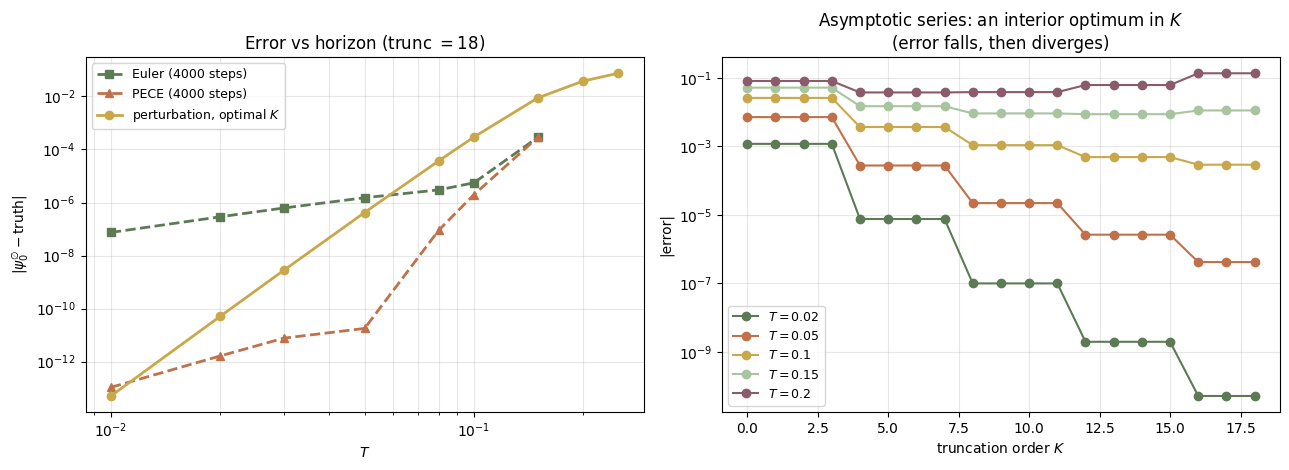

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = axes[0]
Tg = np.array([r_["T"] for r_ in rows])
for name, key, style in [("Euler (4000 steps)", "euler", "s--"), ("PECE (4000 steps)", "pece", "^--"),
                         ("perturbation, optimal $K$", "pert_opt", "o-")]:
    err = [abs(r_[key] - r_["truth"]) if np.isfinite(r_[key]) and abs(r_[key]) < 1e3 else np.nan
           for r_ in rows]
    ax.loglog(Tg, err, style, lw=2, label=name)
ax.set_xlabel("$T$"); ax.set_ylabel(r"$|\psi_0^\varnothing-$truth$|$")
ax.set_title("Error vs horizon (trunc $=18$)"); ax.legend(fontsize=9); ax.grid(True, which="both", alpha=0.3)

ax = axes[1]
for i, T in enumerate([0.02, 0.05, 0.10, 0.15, 0.20]):
    ps = rp.partial_sums(psi, T)
    ax.semilogy(range(len(ps)), np.abs(ps - truth(T)) + 1e-16, "o-",
                color=PALETTE[i % len(PALETTE)], label=f"$T={T}$")
ax.set_xlabel("truncation order $K$"); ax.set_ylabel("|error|")
ax.set_title("Asymptotic series: an interior optimum in $K$\n(error falls, then diverges)")
ax.legend(fontsize=9); ax.grid(True, which="both", alpha=0.3)
fig.tight_layout(); fig.savefig(f"{IMG}/perturbation_vs_ode.pdf", format="pdf", transparent=True)
plt.show()

## 4. Composed variant: restart the expansion every $h$

The hierarchy solves the Riccati equation for *any* terminal data, so it can be restarted: propagate
$\psi$ over a short step $h$ by its own $\tau$-polynomial, then re-expand around the new point. With
$J$ Taylor terms per step this is a Taylor-series integrator of **order $J$ in $h$**, which removes the
series-divergence obstruction.

In [7]:
T = 0.1; ref = truth(T)
print(f"order in h at T={T} (trunc=18); reference = Gauss-Hermite truth\n")
print(f"{'J':>3} " + "".join(f"{'n='+str(n):>11}" for n in [2, 4, 8, 16, 32]) + f"{'slope':>8}")
for J in [1, 2, 3, 4]:
    ns = [2, 4, 8, 16, 32]
    errs = [abs(float(rp.perturbation_solve(p, T, n, J, stab, None).array[0]) - ref) for n in ns]
    slope = np.polyfit(np.log(T/np.array(ns)), np.log(errs), 1)[0]
    print(f"{J:>3} " + "".join(f"{e:>11.1e}" for e in errs) + f"{slope:>8.2f}")
print("\nJ=1 -> slope 1 (Euler), J=2 -> slope 2 (Heun/PECE), as expected for a Taylor method.")
print("J>=3 flattens at ~2e-6: that is the TRUNCATION (closure) floor at trunc=18, T=0.1 --")
print("exactly PECE's error there. The stepper has hit the same wall as every ODE integrator.")

order in h at T=0.1 (trunc=18); reference = Gauss-Hermite truth

  J         n=2        n=4        n=8       n=16       n=32   slope
  1     1.1e-02    4.4e-03    1.9e-03    9.3e-04    4.6e-04    1.15
  2     1.9e-03    4.3e-04    1.1e-04    2.5e-05    4.8e-06    2.13
  3     2.7e-05    1.0e-05    3.1e-06    2.1e-06    2.0e-06    0.98


  4     9.0e-05    3.5e-06    1.8e-06    2.0e-06    2.0e-06    1.19

J=1 -> slope 1 (Euler), J=2 -> slope 2 (Heun/PECE), as expected for a Taylor method.
J>=3 flattens at ~2e-6: that is the TRUNCATION (closure) floor at trunc=18, T=0.1 --
exactly PECE's error there. The stepper has hit the same wall as every ODE integrator.


In [8]:
print("The composed stepper inherits the truncation blow-up, at the same (trunc, T) as Euler/PECE:\n")
print(f"{'T':>6} {'truth':>11} {'PECE(4000)':>12} {'composed J=4':>14}")
for T in [0.05, 0.10, 0.15, 0.20, 0.25]:
    n = max(1, int(np.ceil(T / 0.02)))
    comp = float(rp.perturbation_solve(p, T, n, 4, stab, None).array[0])
    print(f"{T:>6.2f} {truth(T):>11.7f} {show(ode_value(T, 4000, step_fun_pece)):>12}"
          f" {show(comp):>14}")
print("\n=> it fixes the SERIES divergence, not the CLOSURE error. Same conclusion as")
print("   doc/Riccati_scheme_ideas.md: the large-T failure is truncation-induced.")

The composed stepper inherits the truncation blow-up, at the same (trunc, T) as Euler/PECE:

     T       truth   PECE(4000)   composed J=4
  0.05  -0.0072221   -0.0072221     -0.0072213
  0.10  -0.0262941   -0.0262921     -0.0262920
  0.15  -0.0524561   -0.0521707     -0.0521895
  0.20  -0.0820407      blow-up     -0.0633191
  0.25  -0.1128575      blow-up        blow-up

=> it fixes the SERIES divergence, not the CLOSURE error. Same conclusion as
   doc/Riccati_scheme_ideas.md: the large-T failure is truncation-induced.


## 5. `dim = 2`: where the grading actually pays off

At `dim=1` the grade *is* the word length, so $F_k$ coincides with the ordinary truncation and the
structure is invisible. With a time letter (grade 2) the two differ, and two things change.

**A convergent example.** Take $q=-\lambda^2\,\mathbf{22}$ and fold it through the time letter,
$p=q\otimes\mathbf{1}$, so that

$$\langle p,\widehat{\mathbb W}_T\rangle=-\tfrac{\lambda^2}{2}\int_0^T W_s^2\,ds
\qquad\Longrightarrow\qquad
\log\mathbb E\big[e^{\langle p,\widehat{\mathbb W}_T\rangle}\big]=-\tfrac12\log\cosh(\lambda T),$$

by Cameron–Martin — an exact reference. Unlike the quartic, this series **converges**, with radius
$\pi/(2\lambda)$ set by the first zero of $\cosh$.

In [9]:
lam, dim2, trunc2, K2 = 2.0, 2, 12, 12
stab_cm = ta.get_shuffle_table(trunc2, dim2)
q       = ta.from_word(22, trunc2, dim2) * (-lam**2)
p_cm2   = ta.tensor_prod(q, ta.from_word(1, trunc2, dim2))          # append the time letter
print("p =", p_cm2, "  (word 221: length 3, diffusive grade 2*1 + 1 + 1 = 4)")

psi_cm, info_cm = rp.perturbation_hierarchy(p_cm2, K2, stab_cm, time_letter=1, check=True)
ser = rp.taylor_series_in_T(psi_cm)
print("\nhierarchy :", " ".join(f"{c:+.6g} T^{j}" for j, c in enumerate(ser) if abs(c) > 1e-9))
print("exact     : -1/2 log cosh(2T) = -T^2 + 2/3 T^4 - 32/45 T^6 + ...")
print(f"            (-1, {2/3:.6g}, {-32/45:.6g})")
print(f"\nradius of convergence = pi/(2*lam) = {np.pi/(2*lam):.4f}   -> CONVERGENT, unlike the quartic")

p = 

-4.0*221   (word 221: length 3, diffusive grade 2*1 + 1 + 1 = 4)



hierarchy : -1 T^2 +0.666667 T^4 -0.711111 T^6
exact     : -1/2 log cosh(2T) = -T^2 + 2/3 T^4 - 32/45 T^6 + ...
            (-1, 0.666667, -0.711111)

radius of convergence = pi/(2*lam) = 0.7854   -> CONVERGENT, unlike the quartic


In [10]:
exact_cm = lambda T: -0.5*np.log(np.cosh(lam*T))

@jax.jit
def ode_fun2(psi_, args):    # R psi = psi|_1 + 1/2 psi|_22 + 1/2 (psi|_2)^{sh 2}   (dim = 2)
    return (psi_.proj(1) + psi_.proj(22)*0.5
            + ta.shuffle_pow(psi_.proj(2), 2, args["shuffle_table"])*0.5)

def ode_value2(T, n_steps, step_fun):
    res = ode_solver(fun=ode_fun2, step_fun=step_fun, t_grid=jnp.linspace(0.0, T, n_steps+1),
                     init=p_cm2, args={"shuffle_table": stab_cm})
    return float(res.array[0])

print(f"{'T':>6} {'exact':>12} {'Euler':>12} {'PECE':>12} {'pert K=12':>12}"
      f" | {'|e| Euler':>10} {'|e| PECE':>10} {'|e| pert':>10}")
for T in [0.1, 0.2, 0.3, 0.5, 0.7]:
    ex = exact_cm(T); ps = rp.partial_sums(psi_cm, T)[-1]
    eu, pe = ode_value2(T, 4000, step_fun_euler), ode_value2(T, 4000, step_fun_pece)
    print(f"{T:>6.2f} {ex:>12.8f} {eu:>12.8f} {pe:>12.8f} {ps:>12.8f}"
          f" | {abs(eu-ex):>10.1e} {abs(pe-ex):>10.1e} {abs(ps-ex):>10.1e}")
print("\nHere the perturbation series converges, so raising K keeps helping -- but at K=12 only")
print("three terms are populated (p has grade 4), so PECE still wins at larger T.")

     T        exact        Euler         PECE    pert K=12 |  |e| Euler   |e| PECE   |e| pert


  0.10  -0.00993404  -0.00993160  -0.00993404  -0.00993404 |    2.4e-06    4.0e-12    8.5e-09


  0.20  -0.03897674  -0.03896772  -0.03897674  -0.03897884 |    9.0e-06    5.4e-11    2.1e-06


  0.30  -0.08506764  -0.08504963  -0.08506764  -0.08511840 |    1.8e-05    2.1e-10    5.1e-05


  0.50  -0.21689042  -0.21685431  -0.21689042  -0.21944444 |    3.6e-05    7.2e-10    2.6e-03


  0.70  -0.38294282  -0.38289395  -0.38294282  -0.41359484 |    4.9e-05    6.7e-10    3.1e-02

Here the perturbation series converges, so raising K keeps helping -- but at K=12 only
three terms are populated (p has grade 4), so PECE still wins at larger T.


In [11]:
# the dimension argument: grade truncation vs length truncation at dim = 2
print("Truncating by diffusive grade keeps EXACTLY the words that matter to a given order in eps.\n")
print(f"{'K':>4} {'dim F_K (grade<=K)':>20} {'#words (length<=K)':>20} {'ratio':>8}")
for k in [4, 6, 8, 10, 12, 14, 16, 18, 20]:
    fib = np.zeros(k + 4, dtype=object); fib[1] = 1
    for i in range(2, k + 4): fib[i] = fib[i-1] + fib[i-2]
    dF, nl = int(fib[k + 3]) - 1, 2**(k + 1) - 1
    print(f"{k:>4} {dF:>20d} {nl:>20d} {nl/dF:>8.1f}x")
print("\ndim F_K = Fib(K+3) - 1 (words are compositions of K into parts 1 and 2).")
print("At K=20 that is a 73x reduction. NOTE: the current dense TensorSequence stores the full")
print("length-truncated algebra, so this saving is POTENTIAL -- realizing it needs level-sparse")
print("storage. grade_truncation_mask() projects onto F_K but does not shrink the arrays.")

Truncating by diffusive grade keeps EXACTLY the words that matter to a given order in eps.

   K   dim F_K (grade<=K)   #words (length<=K)    ratio
   4                   12                   31      2.6x
   6                   33                  127      3.8x
   8                   88                  511      5.8x
  10                  232                 2047      8.8x
  12                  609                 8191     13.4x
  14                 1596                32767     20.5x
  16                 4180               131071     31.4x
  18                10945               524287     47.9x
  20                28656              2097151     73.2x

dim F_K = Fib(K+3) - 1 (words are compositions of K into parts 1 and 2).
At K=20 that is a 73x reduction. NOTE: the current dense TensorSequence stores the full
length-truncated algebra, so this saving is POTENTIAL -- realizing it needs level-sparse
storage. grade_truncation_mask() projects onto F_K but does not shrink the arrays.


## 6. Summary

| | single-shot hierarchy | composed (restart every $h$) | Euler / PECE |
|---|---|---|---|
| time-discretization error | **none** (exact polynomial in $\tau$) | $O(h^J)$ | $O(h)$ / $O(h^2)$ |
| nonlinearity | **linear at every order** (triangular, in fact diagonal) | linear per step | nonlinear |
| output | **closed-form $T$-series** | value only | value only |
| range in $T$ | limited by the $\varepsilon$-series radius (zero for $-W_T^4$) | unlimited in principle | unlimited in principle |
| large-$T$ failure | series divergence | **truncation blow-up** | **truncation blow-up** |

**What the idea delivers.** The grading turns the Riccati equation into a triangular system of *linear*
ODEs with nilpotent generator, hence exactly solvable as polynomials in $\tau$ — no time grid, no
nonlinear solve, no discretization error. It yields the analytic small-time expansion of the transform
(here $-3T^2+48T^4-1584T^6+78336T^8$, matching the moment expansion), which is an output no ODE
integrator gives. The diagonality $k=\gamma+2j$ makes the truncation a triangle in (grade, time degree),
and at `dim`$\ge2$ that triangle is dramatically smaller than the length truncation.

**What it does not deliver.** Summed at $\varepsilon=1$ it is *numerically identical* to the plain
recursive $\tau$-Taylor method, so the grading is structure and truncation strategy, not a new number.
On the $-W_T^4$ benchmark the series is asymptotic and only four orders are populated, so PECE with a
converged step count is more accurate for $T\gtrsim0.02$. And composing it into a stepper to reach large
$T$ turns it into a high-order Taylor integrator that hits the *same* truncation-induced blow-up as
Euler/PECE — consistent with [`doc/Riccati_scheme_ideas.md`](../doc/Riccati_scheme_ideas.md).

**Where it is the right tool:** small-time/small-data regimes, analytic expansions, and problems whose
$\varepsilon$-series converges (quadratic functionals such as the Cameron–Martin and Lévy-area families).